# ML-08 — Capstone Modeling Lane

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/octane21/flyrank-internship-ML/blob/main/work/notebooks/w05_model.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Method choice and why

*Which method from the toolkit, and why it fits your lane.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 2. Split design

*Grouped by client? Time-aware? Say why this split is honest for your question.*

In [8]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

import pandas as pd

dataset = pd.read_csv('dataset.csv')


dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45019 entries, 0 to 45018
Data columns (total 77 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Unnamed: 0                       45019 non-null  int64  
 1   client_hash_id                   45019 non-null  object 
 2   content_hash_id                  45019 non-null  object 
 3   month                            45019 non-null  object 
 4   gsc_impressions_30d              45019 non-null  int64  
 5   gsc_clicks_30d                   45019 non-null  int64  
 6   gsc_sum_position_30d             45019 non-null  int64  
 7   ga4_pageviews_30d                45019 non-null  int64  
 8   ga4_sessions_30d                 45019 non-null  int64  
 9   ga4_users_30d                    45019 non-null  int64  
 10  ga4_engaged_sessions_30d         45019 non-null  int64  
 11  sessions_ai_30d                  45019 non-null  int64  
 12  sessions_organic_3

In [23]:
features = [
    'client_hash_id',
    'content_hash_id',
    'month',
    'gsc_impressions_30d',
    'gsc_clicks_30d',
    'gsc_sum_position_30d',
    'ga4_pageviews_30d',
    'ga4_sessions_30d',
    'ga4_users_30d',
    'ga4_engaged_sessions_30d',
    'sessions_ai_30d',
    'sessions_organic_30d',
    'scroll_events_30d',
    'ga4_data_available',
    'gsc_data_available',
    'gsc_avg_position_30d',
    'gsc_impressions_prev_30d',
    'gsc_impressions_2m_ago_30d',
    'gsc_clicks_prev_30d',
    'gsc_clicks_2m_ago_30d',
    'gsc_sum_position_prev_30d',
    'gsc_sum_position_2m_ago_30d',
    'ga4_pageviews_prev_30d',
    'ga4_pageviews_2m_ago_30d',
    'ga4_sessions_prev_30d',
    'ga4_sessions_2m_ago_30d',
    'ga4_users_prev_30d',
    'ga4_users_2m_ago_30d',
    'ga4_engaged_sessions_prev_30d',
    'ga4_engaged_sessions_2m_ago_30d',
    'sessions_ai_prev_30d',
    'sessions_ai_2m_ago_30d',
    'sessions_organic_prev_30d',
    'sessions_organic_2m_ago_30d',
    'scroll_events_prev_30d',
    'scroll_events_2m_ago_30d',
    'gsc_avg_position_prev_30d',
    'gsc_avg_position_2m_ago_30d',
    'content_type',
    'search_volume',
    'competition',
    'competition_level',
    'cpc',
    'main_intent',
    'backlinks',
    'category_count',
    'word_count',
    'char_count',
    'content_age_days',
    'ctr_30d',
    'engagement_rate_30d',
    'scroll_rate_30d',
    'ai_traffic_30d',
    'decline_future_label'
]

label = ['decline_future_label']

dataset_90d = dataset[features].copy()

dataset_90d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45019 entries, 0 to 45018
Data columns (total 54 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   client_hash_id                   45019 non-null  object 
 1   content_hash_id                  45019 non-null  object 
 2   month                            45019 non-null  object 
 3   gsc_impressions_30d              45019 non-null  int64  
 4   gsc_clicks_30d                   45019 non-null  int64  
 5   gsc_sum_position_30d             45019 non-null  int64  
 6   ga4_pageviews_30d                45019 non-null  int64  
 7   ga4_sessions_30d                 45019 non-null  int64  
 8   ga4_users_30d                    45019 non-null  int64  
 9   ga4_engaged_sessions_30d         45019 non-null  int64  
 10  sessions_ai_30d                  45019 non-null  int64  
 11  sessions_organic_30d             45019 non-null  int64  
 12  scroll_events_30d 

In [28]:
dataset_90d = dataset_90d.copy()

dataset_90d = dataset_90d.replace(
    [np.inf, -np.inf],
    np.nan
)

In [29]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


target_col = 'decline_future_label'
group_col = 'client_hash_id'

X = dataset_90d.drop(
    columns=[target_col, group_col]
)

y = dataset_90d[target_col]

groups = dataset_90d[group_col]

numeric_features = X.select_dtypes(
    include=['number']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])


preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
}

gkf = GroupKFold(
    n_splits=5
)

results = []

for fold, (train_idx, test_idx) in enumerate(
    gkf.split(X, y, groups=groups),
    start=1
):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    train_groups = groups.iloc[train_idx]
    test_groups = groups.iloc[test_idx]

    # Validasi group leakage
    assert set(train_groups).isdisjoint(
        set(test_groups)
    )

    for model_name, model in models.items():

        pipeline = Pipeline([
            ('preprocessor', preprocessor),
            ('classifier', model)
        ])

        # Training
        pipeline.fit(X_train, y_train)

        # Prediction
        y_pred = pipeline.predict(X_test)

        y_proba = pipeline.predict_proba(X_test)[:, 1]

        # Evaluation
        results.append({
            'model': model_name,
            'fold': fold,

            'train_rows': len(train_idx),
            'test_rows': len(test_idx),

            'train_clients': train_groups.nunique(),
            'test_clients': test_groups.nunique(),

            'accuracy': accuracy_score(
                y_test, y_pred
            ),

            'precision': precision_score(
                y_test, y_pred, zero_division=0
            ),

            'recall': recall_score(
                y_test, y_pred, zero_division=0
            ),

            'f1': f1_score(
                y_test, y_pred, zero_division=0
            ),

            'roc_auc': roc_auc_score(
                y_test, y_proba
            )
        })

results_df = pd.DataFrame(results)

results_df

,model,fold,train_rows,test_rows,train_clients,test_clients,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,1,18163,26856,18,1,0.504431,0.436279,0.484817,0.459269,0.500089
1,Random Forest,1,18163,26856,18,1,0.438003,0.435720,0.998628,0.606718,0.679464
2,Logistic Regression,2,33640,11379,18,1,0.544775,0.132340,0.086236,0.104426,0.198701
3,Random Forest,2,33640,11379,18,1,0.692240,0.000000,0.000000,0.000000,0.425841
4,Logistic Regression,3,42439,2580,18,1,0.492248,0.317774,0.391593,0.350842,0.409575
5,Random Forest,3,42439,2580,18,1,0.657752,0.515789,0.379425,0.437221,0.672047
6,Logistic Regression,4,42913,2106,14,5,0.814340,0.820000,0.975595,0.891056,0.580544
7,Random Forest,4,42913,2106,14,5,0.773504,0.895238,0.802929,0.846574,0.808578
8,Logistic Regression,5,42921,2098,8,11,0.558627,0.534286,0.893881,0.668813,0.568752
9,Random Forest,5,42921,2098,8,11,0.505720,0.506706,0.325048,0.396040,0.557042


In [27]:
# Memeriksa kolom numerik
numeric_cols = dataset_90d.select_dtypes(
    include='number'
).columns

inf_counts = np.isinf(
    dataset_90d[numeric_cols]
).sum()

print(
    inf_counts[inf_counts > 0]
)

scroll_rate_30d    11
dtype: int64


In [30]:
summary = (
    results_df
    .groupby('model')
    .agg({
        'accuracy': ['mean', 'std'],
        'precision': ['mean', 'std'],
        'recall': ['mean', 'std'],
        'f1': ['mean', 'std'],
        'roc_auc': ['mean', 'std']
    })
)

summary

accuracy           precision              recall  \
                         mean       std      mean       std      mean   
model                                                                   
Logistic Regression  0.582884  0.132271  0.448136  0.256206  0.566425   
Random Forest        0.613444  0.138000  0.470691  0.318726  0.501206   

                                     f1             roc_auc            
                          std      mean       std      mean       std  
model                                                                  
Logistic Regression  0.368258  0.494881  0.300698  0.451532  0.156865  
Random Forest        0.398602  0.457311  0.311103  0.628594  0.144134

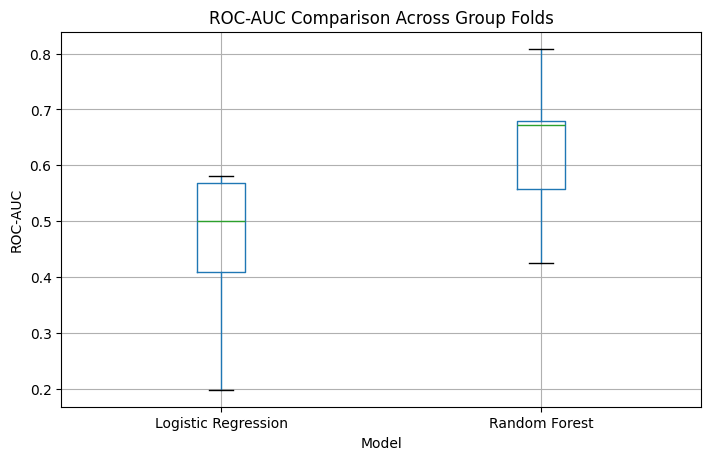

In [31]:
import matplotlib.pyplot as plt

results_df.boxplot(
    column='roc_auc',
    by='model',
    figsize=(8, 5)
)

plt.title('ROC-AUC Comparison Across Group Folds')
plt.suptitle('')
plt.xlabel('Model')
plt.ylabel('ROC-AUC')
plt.show()

In [32]:
train_idx, test_idx = next(
    gkf.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

best_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.01      0.02     15198
           1       0.44      1.00      0.61     11658

    accuracy                           0.44     26856
   macro avg       0.66      0.50      0.31     26856
weighted avg       0.69      0.44      0.27     26856

[[  121 15077]
 [   16 11642]]


In [33]:
for fold, (_, test_idx) in enumerate(
    gkf.split(X, y, groups=groups),
    start=1
):
    print(f"\nFold {fold}")

    print(
        y.iloc[test_idx].value_counts(normalize=True)
    )


Fold 1
decline_future_label
0    0.565907
1    0.434093
Name: proportion, dtype: float64

Fold 2
decline_future_label
0    0.69224
1    0.30776
Name: proportion, dtype: float64

Fold 3
decline_future_label
0    0.649612
1    0.350388
Name: proportion, dtype: float64

Fold 4
decline_future_label
1    0.778253
0    0.221747
Name: proportion, dtype: float64

Fold 5
decline_future_label
0    0.50143
1    0.49857
Name: proportion, dtype: float64


## 3. Train + compare vs my baseline

*Same data, same metric, same split as your Week-4 baseline. Show the table.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 4. Errors and interpretation

*Where is the model wrong? What does it lean on? A short error analysis beats a big metric table.*

In [ ]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.